# C - Validation, change through time, research question (C1-C5)

In [1]:
import sys; sys.path.insert(0, "..")            # so the notebook finds helpers.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import helpers as H

EP = H.epochs()                                  # all epochs found in data/merged
R = {e: H.process(e) for e in EP}                # ground / vegetation separation: slow the first time, cached afterwards
print([H.EPOCH_LABEL[e] for e in EP])
TT = {e: H.tussocks(R[e], alpha=False) for e in EP}                               # tussocks of every epoch
BL = pd.concat([H.blocks(R[e], TT[e]) for e in EP], ignore_index=True)           # 5 m blocks of every epoch
BC = H.common_area(BL)                                                           # blocks with LiDAR data in ALL epochs
print(f"Common area: {len(BC[BC.epoch == EP[0]]) * H.BLOCK_M ** 2:.0f} m2")

['Feb 2024', 'May 2024', 'Jun 2024', 'Jul 2024', 'Mar 2025', 'May 2025', 'Feb 2026', 'Oct 2026']


Common area: 46375 m2


## C1 - Quality check of the biomass estimate
### (a) Manual biomass samples (destructive sampling, Sander Vos)

In [2]:
import os
f = H.ROOT / "data" / "biomass_measurements.csv"
S = pd.read_csv(f); S.columns = ["x", "y", "measured_g_per_m3"]          # 7 samples: x, y (RD) and dry biomass in g per m3
E = "20250327" if "20250327" in EP else EP[-1]; g = R[E]["grid_dtm"]; v = R[E]["veg"]
inside = (S.x > g["x0"]) & (S.x < g["x0"] + g["nc"] * g["res"]) & (S.y < g["y1"]) & (S.y > g["y1"] - g["nr"] * g["res"])
print(f"{inside.sum()} of {len(S)} samples lie inside the study area; epoch used: {H.EPOCH_LABEL[E]}")
if inside.sum() == 0: print("-> clip the area around the samples (see README) and change BOX in helpers.py")
rows = []
for _, s in S[inside].iterrows():
    m = np.hypot(v["x"] - s.x, v["y"] - s.y) < 1.0                              # vegetation points within 1 m of the sample
    xyh = np.column_stack([v["x"][m], v["y"][m], v["hag"][m]])
    vol = H.vol_column(xyh) if m.sum() > 5 else 0.0
    rows.append({"x": s.x, "y": s.y, "measured (g/m3)": s.measured_g_per_m3, "veg points within 1 m": int(m.sum()),
                 "LiDAR canopy volume (m3)": round(vol, 3), "max height (m)": round(float(v["hag"][m].max()), 2) if m.any() else 0.0,
                 "veg points per m3": round(m.sum() / vol, 0) if vol > 0 else np.nan})
H.table(pd.DataFrame(rows), "C1_biomass_samples")

7 of 7 samples lie inside the study area; epoch used: Mar 2025


,x,y,measured (g/m3),veg points within 1 m,LiDAR canopy volume (m3),max height (m),veg points per m3
0,72480.585,451435.528,17.5,0,0.000,0.00,NaN
1,72489.188,451498.822,1640.0,68,0.117,0.45,582.0
2,72438.419,451504.341,67.5,0,0.000,0.00,NaN
3,72383.018,451603.151,80.0,0,0.000,0.00,NaN
4,72314.095,451555.211,1502.5,53,0.075,0.29,709.0
5,72358.243,451613.362,8647.5,19,0.028,0.29,670.0
6,72379.401,451541.578,92.5,0,0.000,0.00,NaN


In [3]:
meas = S.measured_g_per_m3 / 1000                                   # kg per m3, same unit as rho
print("Measured density (kg/m3): min %.3f | 25 %% %.3f | median %.3f | 75 %% %.3f | max %.3f" % (meas.min(), meas.quantile(.25), meas.median(), meas.quantile(.75), meas.max()))
print("Placeholder rho (kg/m3):", H.RHO)

Measured density (kg/m3): min 0.018 | 25 % 0.074 | median 0.092 | 75 % 1.571 | max 8.648
Placeholder rho (kg/m3): {'low': 0.3, 'mid': 0.8, 'high': 1.4}


**To write (C1a):** the measured values are biomass per m3 - the same quantity as rho - so they test the conversion directly: where do low / mid / high rho sit in the measured distribution? Set rho from the measured quartiles (25 % / median / 75 %) if the sampled volume is the canopy volume (ask Sander how the volume was defined). Only a few samples: this is a plausibility check, not a calibration or machine learning.

### (b) Noise floor of ground change and (c) agreement of the volume methods

In [4]:
rows = []
for a, b in zip(EP[:-1], EP[1:]):
    d, lod = H.ground_change(R[a], R[b]); rows.append({"from": H.EPOCH_LABEL[a], "to": H.EPOCH_LABEL[b], "median change (m)": round(lod["median"], 3), "sigma (m)": round(lod["sigma"], 3), "LoD 95% (m)": round(lod["lod95"], 3)})
H.table(pd.DataFrame(rows), "C1_level_of_detection")

,from,to,median change (m),sigma (m),LoD 95% (m)
0,Feb 2024,May 2024,0.005,0.098,0.192
1,May 2024,Jun 2024,0.019,0.027,0.054
2,Jun 2024,Jul 2024,-0.000,0.040,0.078
3,Jul 2024,Mar 2025,0.051,0.119,0.232
4,Mar 2025,May 2025,0.000,0.022,0.044
5,May 2025,Feb 2026,0.030,0.148,0.291
6,Feb 2026,Oct 2026,-0.014,0.072,0.141


In [5]:
tv = H.tussocks(R[E])
print("Rank agreement of the volume estimators (Spearman):"); tv[["vol_column", "vol_hull", "vol_voxel", "vol_alpha"]].corr(method="spearman").round(2)

Rank agreement of the volume estimators (Spearman):


,vol_column,vol_hull,vol_voxel,vol_alpha
vol_column,1.00,0.97,0.91,0.85
vol_hull,0.97,1.00,0.88,0.81
vol_voxel,0.91,0.88,1.00,0.88
vol_alpha,0.85,0.81,0.88,1.00


## C2 - Maps of vegetation and biomass, and what drives them

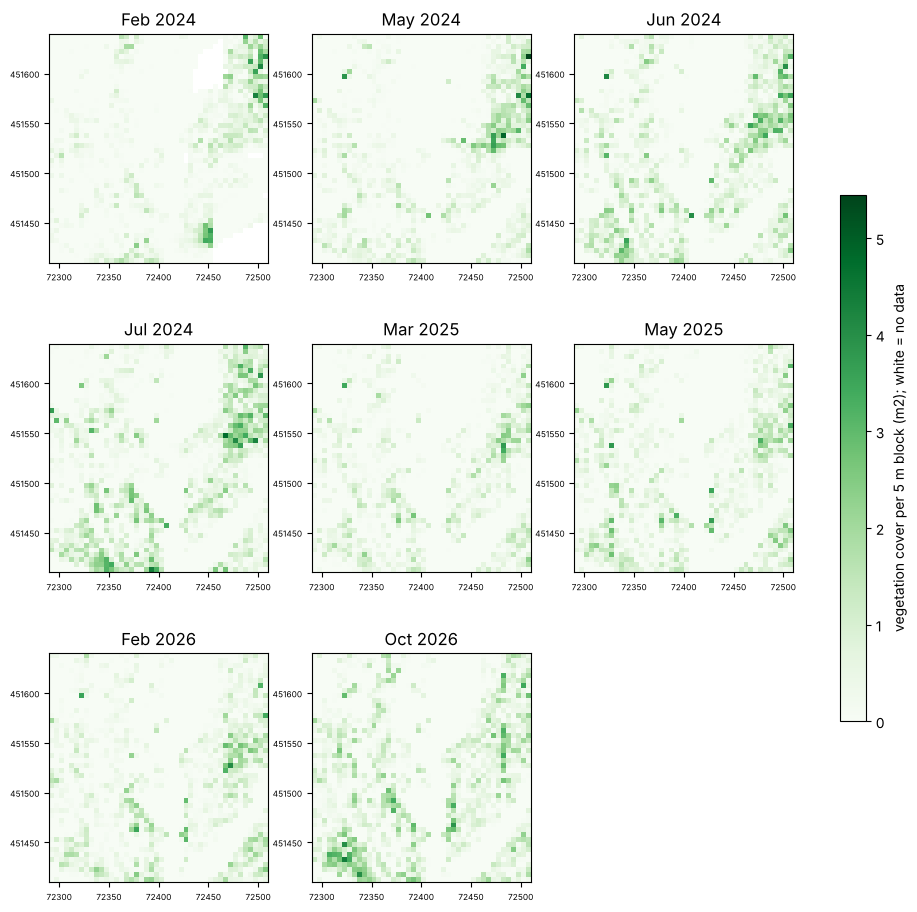

In [6]:
n = len(EP); cols = 3; fig, axs = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(12, 3.8 * int(np.ceil(n / cols)))); axs = axs.ravel()
for k, e in enumerate(EP):
    s = BL[BL.epoch == e].copy(); s.loc[s.data_share <= .5, "cover_m2"] = np.nan; g = R[e]["grid_dtm"]
    im = axs[k].imshow(H.block_image(s, "cover_m2"), extent=H.extent(g), cmap="Greens", vmin=0, vmax=BL.cover_m2.max()); axs[k].set_title(H.EPOCH_LABEL[e]); axs[k].tick_params(labelsize=6)
for a in axs[n:]: a.axis("off")
fig.colorbar(im, ax=axs, label="vegetation cover per 5 m block (m2); white = no data", shrink=.6); H.save(fig, "C2_cover_maps")

In [7]:
from scipy.stats import spearmanr
rows = []
for e in EP:
    s = BC[BC.epoch == e]
    for drv in ["slope_deg", "z_nap"]:
        r_, p_ = spearmanr(s[drv], s.agb_mid_kg, nan_policy="omit"); rows.append({"epoch": H.EPOCH_LABEL[e], "driver": drv, "spearman r": round(r_, 2), "p": round(p_, 4)})
H.table(pd.DataFrame(rows), "C2_driver_correlations").pivot(index="epoch", columns="driver", values="spearman r").loc[[H.EPOCH_LABEL[e] for e in EP]]

driver,slope_deg,z_nap
epoch,,
Feb 2024,0.14,-0.06
May 2024,0.23,0.02
Jun 2024,0.34,0.18
Jul 2024,0.27,0.14
Mar 2025,0.26,0.19
May 2025,0.25,0.20
Feb 2026,0.20,0.13
Oct 2026,0.22,0.28


**To write (C2):** compare with what you expect for a juvenile dune (vegetation behind the beach, on higher / sheltered parts; exposure to wind and water; distance to the shoreline). z_nap = height of the block in NAP.

## C3 - Change through time (common area only)

In [8]:
g_ = BC.groupby("epoch")
ts = pd.DataFrame({"epoch": [H.EPOCH_LABEL[e] for e in EP], "cover_m2": [g_.cover_m2.sum()[e] for e in EP], "tussocks": [g_.n_tussocks.sum()[e] for e in EP],
                   "volume_m3": [g_.vol_m3.sum()[e] for e in EP], "biomass_mid_kg": [g_.agb_mid_kg.sum()[e] for e in EP]})
ts["biomass_low_kg"] = ts.biomass_mid_kg * H.RHO["low"] / H.RHO["mid"]; ts["biomass_high_kg"] = ts.biomass_mid_kg * H.RHO["high"] / H.RHO["mid"]
H.table(ts.round(2), "C3_timeseries")

,epoch,cover_m2,tussocks,volume_m3,biomass_mid_kg,biomass_low_kg,biomass_high_kg
0,Feb 2024,395.69,505.0,68.44,54.75,20.53,95.82
1,May 2024,462.15,609.0,95.26,76.20,28.58,133.36
2,Jun 2024,685.12,1023.0,137.60,110.08,41.28,192.64
3,Jul 2024,769.45,1063.0,160.45,128.36,48.13,224.63
4,Mar 2025,396.52,617.0,71.71,57.37,21.51,100.40
5,May 2025,522.25,789.0,102.07,81.66,30.62,142.90
6,Feb 2026,485.69,746.0,89.38,71.50,26.81,125.13
7,Oct 2026,797.11,1192.0,162.58,130.06,48.77,227.61


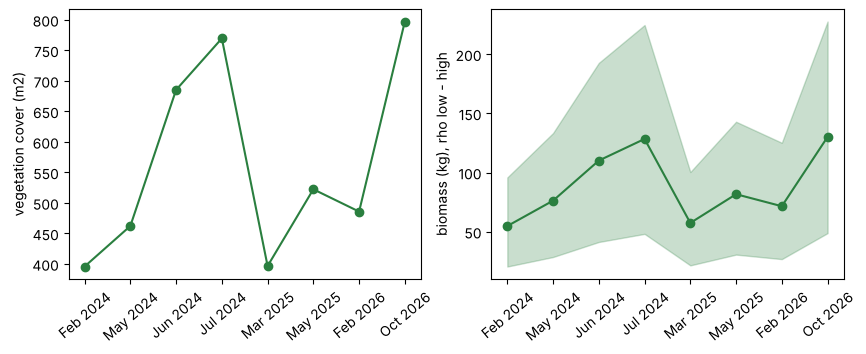

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ts.epoch, ts.cover_m2, "o-", c="#2a7f3f"); ax[0].set_ylabel("vegetation cover (m2)")
ax[1].fill_between(ts.epoch, ts.biomass_low_kg, ts.biomass_high_kg, color="#2a7f3f", alpha=.25); ax[1].plot(ts.epoch, ts.biomass_mid_kg, "o-", c="#2a7f3f"); ax[1].set_ylabel("biomass (kg), rho low - high")
for a in ax: a.tick_params(axis="x", rotation=40)
H.save(fig, "C3_timeseries")

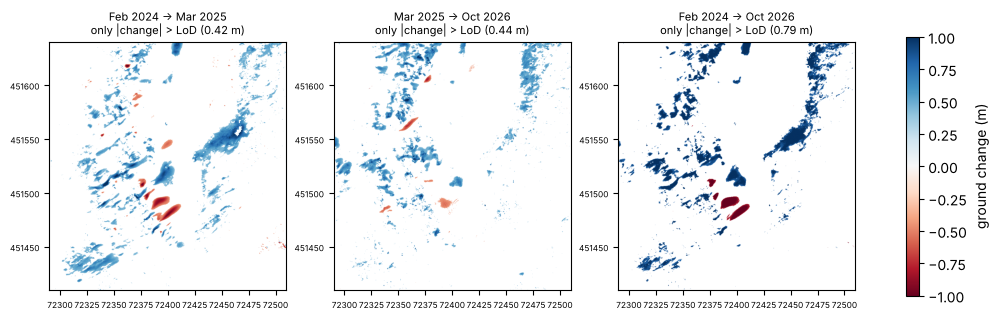

In [10]:
pairs = [(EP[0], EP[len(EP) // 2]), (EP[len(EP) // 2], EP[-1]), (EP[0], EP[-1])]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (a, b) in zip(axs, pairs):
    d, lod = H.ground_change(R[a], R[b]); m = np.where(np.abs(d) > lod["lod95"], d, np.nan)
    im = ax.imshow(m, extent=H.extent(R[a]["grid_dtm"]), cmap="RdBu", vmin=-1, vmax=1); ax.tick_params(labelsize=6)
    ax.set_title(f"{H.EPOCH_LABEL[a]} -> {H.EPOCH_LABEL[b]}\nonly |change| > LoD ({lod['lod95']:.2f} m)", fontsize=8)
fig.colorbar(im, ax=axs, label="ground change (m)", shrink=.8); H.save(fig, "C3_ground_change")

In [11]:
a, b = BL[(BL.epoch == EP[0]) & (BL.data_share > .9)], BL[(BL.epoch == EP[-1]) & (BL.data_share > .9)]
hot = a.merge(b, on=["row", "col"], suffixes=("_first", "_last"))                 # only blocks with data in both epochs
hot = pd.DataFrame({"x": hot.x_first, "y": hot.y_first, "slope_deg": hot.slope_deg_first.round(1), "biomass_first_kg": hot.agb_mid_kg_first.round(2),
                    "biomass_last_kg": hot.agb_mid_kg_last.round(2)}); hot["change_kg"] = (hot.biomass_last_kg - hot.biomass_first_kg).round(2)
H.table(pd.concat([hot.nsmallest(5, "change_kg"), hot.nlargest(5, "change_kg")]), "C3_hotspots")

,x,y,slope_deg,biomass_first_kg,biomass_last_kg,change_kg
306,72497.5,451602.5,5.0,1.24,0.15,-1.09
501,72497.5,451577.5,5.0,1.05,0.12,-0.93
158,72502.5,451622.5,3.3,0.88,0.00,-0.88
458,72502.5,451582.5,5.9,0.88,0.00,-0.88
196,72502.5,451617.5,2.6,0.73,0.06,-0.67
1657,72307.5,451437.5,3.1,0.00,1.32,1.32
1473,72432.5,451462.5,7.1,0.00,1.28,1.28
1661,72327.5,451437.5,6.8,0.00,1.23,1.23
1697,72322.5,451432.5,5.4,0.00,1.11,1.11
1257,72432.5,451487.5,1.1,0.00,1.06,1.06


**To write (C3):** total change in cover and biomass, the largest losses and gains (hotspots), and the drivers (season, sand burial / erosion, wind). Compare any big step between epochs with the level of detection and with acquisition differences before calling it real change.

## Research question - does biomass differ between dune slopes?

,slope_class,blocks,agb_mid_kg,cover_m2
0,0-5,8419,0.033,0.209
1,5-10,4862,0.061,0.383
2,10-15,1311,0.088,0.568
3,>15,248,0.086,0.572


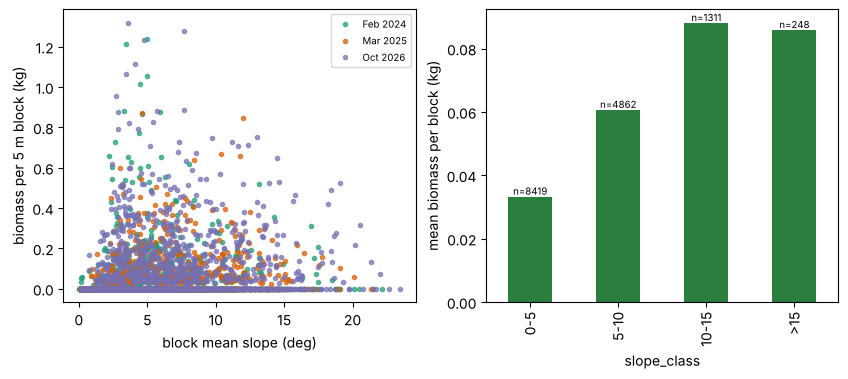

In [12]:
s = BC.copy(); s["slope_class"] = pd.cut(s.slope_deg, [-1, 5, 10, 15, 90], labels=["0-5", "5-10", "10-15", ">15"])
mean = s.groupby("slope_class", observed=True)[["agb_mid_kg", "cover_m2"]].mean(); mean.insert(0, "blocks", s.groupby("slope_class", observed=True).size())
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for e, c in zip([EP[0], EP[len(EP) // 2], EP[-1]], ["#1b9e77", "#d95f02", "#7570b3"]):
    q = s[s.epoch == e]; axs[0].plot(q.slope_deg, q.agb_mid_kg, ".", c=c, alpha=.7, label=H.EPOCH_LABEL[e])
axs[0].set_xlabel("block mean slope (deg)"); axs[0].set_ylabel("biomass per 5 m block (kg)"); axs[0].legend(fontsize=7)
mean.agb_mid_kg.plot.bar(ax=axs[1], color="#2a7f3f"); axs[1].set_ylabel("mean biomass per block (kg)")
for i, n_ in enumerate(mean.blocks): axs[1].text(i, mean.agb_mid_kg.iloc[i], f"n={n_}", ha="center", va="bottom", fontsize=7)
H.save(fig, "RQ_biomass_vs_slope"); H.table(mean.round(3).reset_index(), "RQ_slope_classes")

In [13]:
from scipy.stats import rankdata
def partial(x, y, z):                                  # Spearman correlation of x and y after removing the effect of z
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    return np.corrcoef(rx - np.polyval(np.polyfit(rz, rx, 1), rz), ry - np.polyval(np.polyfit(rz, ry, 1), rz))[0, 1]
rows = []
for e in EP:
    q = s[(s.epoch == e) & s.z_nap.notna()]
    r_, p_ = spearmanr(q.slope_deg, q.agb_mid_kg); rows.append({"epoch": H.EPOCH_LABEL[e], "blocks": len(q), "spearman (slope, biomass)": round(r_, 2), "p": round(p_, 4),
                                                              "partial, elevation held fixed": round(partial(q.slope_deg, q.agb_mid_kg, q.z_nap), 2)})
H.table(pd.DataFrame(rows), "RQ_slope_correlations")

,epoch,blocks,"spearman (slope, biomass)",p,"partial, elevation held fixed"
0,Feb 2024,1855,0.14,0.0,0.20
1,May 2024,1855,0.23,0.0,0.24
2,Jun 2024,1855,0.34,0.0,0.29
3,Jul 2024,1855,0.27,0.0,0.23
4,Mar 2025,1855,0.26,0.0,0.20
5,May 2025,1855,0.25,0.0,0.19
6,Feb 2026,1855,0.20,0.0,0.16
7,Oct 2026,1855,0.22,0.0,0.11


**To write (RQ):** direction and strength of the slope - biomass relation, whether it survives with elevation held fixed (partial correlation), and confounding: biomass depends on elevation / distance to the sea, burial and wind exposure as well as slope; vegetation detection can also be biased on steep slopes.

## C4 - Discussion
How the vegetation and biomass patterns may influence dune development at the Zandmotor, and whether your data are sufficient or only indicative (number of epochs, one small area, placeholder or few-sample rho).

## C5 - Reflection
How this LiDAR workflow compares with satellite imagery and manual sampling; recommendations to improve the estimates and the quality assessment (more biomass samples, species map, repeat GNSS on bare sand, density-matched acquisitions).